<a href="https://colab.research.google.com/github/hemant-rawani9/HorizonTechX_DATA-SCIENCE/blob/main/Sales_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Sales Prediction Project

* **Goal:** Predict future sales based on factors like advertising spend, target audience, and platform.
* **Process:**
  * Clean, transform, and prepare datasets for analysis.
  * Apply regression or time-series forecasting models.
  * Analyze how changes in advertising strategies impact sales outcomes.
  * Deliver actionable insights to support business and marketing decisions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Set plotting style
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

#### Load the Sales Dataset

Replace `'sales.csv'` below with the correct path to your sales CSV dataset file.

In [3]:
# Generate a synthetic sales dataset and save it as 'sales.csv'
import numpy as np
import pandas as pd

# Seed for reproducibility
np.random.seed(42)

n_samples = 200
tv_spend = np.random.uniform(10, 300, n_samples)
radio_spend = np.random.uniform(5, 50, n_samples)
newspaper_spend = np.random.uniform(2, 80, n_samples)

# Sales formula with some random noise
sales = 5 + 0.05 * tv_spend + 0.18 * radio_spend + 0.005 * newspaper_spend + np.random.normal(0, 1.5, n_samples)

synthetic_data = pd.DataFrame({
    'TV': tv_spend,
    'Radio': radio_spend,
    'Newspaper': newspaper_spend,
    'Sales': sales
})

# Save to CSV
synthetic_data.to_csv('sales.csv', index=False)
print("Synthetic 'sales.csv' successfully created!")

# Load and display the dataset
df = pd.read_csv('sales.csv')
display(df.head())
display(df.info())

Synthetic 'sales.csv' successfully created!


,TV,Radio,Newspaper,Sales
0,118.616634,33.891424,10.043662,16.286120
1,285.707149,8.786298,72.399127,20.039578
2,222.278243,12.273292,41.409685,18.369608
3,183.610960,45.434938,66.463682,21.138292
4,55.245406,32.289308,26.963869,12.878691


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


None

#### Step 1: Exploratory Data Analysis (EDA)

Let's visualize the correlation and scatter plots between each advertising medium (TV, Radio, Newspaper) and Sales.

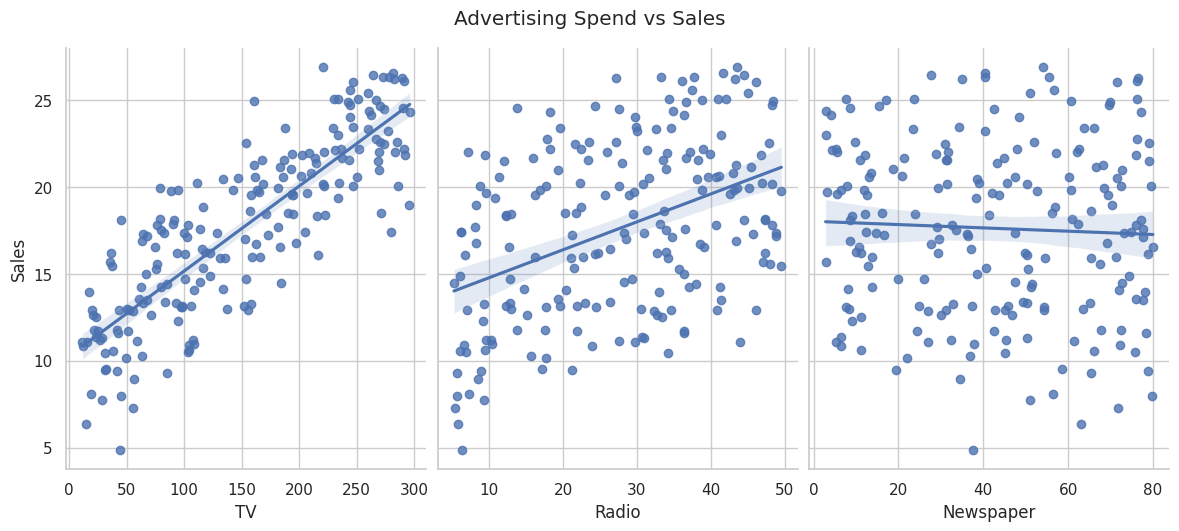

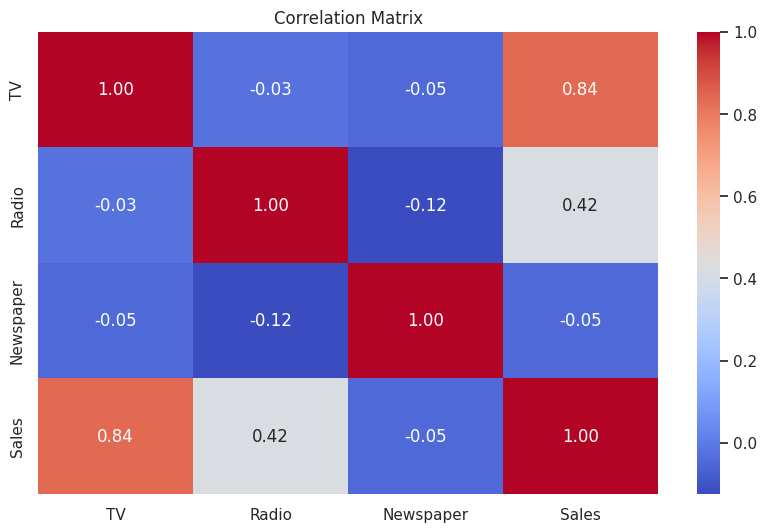

In [4]:
# Pairplot to visualize relationships
sns.pairplot(df, x_vars=['TV', 'Radio', 'Newspaper'], y_vars='Sales', height=5, aspect=0.8, kind='reg')
plt.suptitle('Advertising Spend vs Sales', y=1.05)
plt.show()

# Correlation Matrix
splt = sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

#### Step 2: Model Training and Evaluation

We will split the dataset into training (80%) and testing (20%) sets, train a Multiple Linear Regression model, and evaluate its performance.

In [5]:
# Define features and target variable
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict on the test set
y_pred = model.predict(X_test)

# Calculate metrics
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R-squared (R2) Score: {r2:.4f}")

Mean Squared Error (MSE): 1.5534
R-squared (R2) Score: 0.9374


#### Step 3: Actionable Insights and Impact Analysis

Let's extract the model coefficients to determine how changes in advertising budgets impact overall sales outcomes.

Model Coefficients and Intercept:


,Coefficient
TV,0.049262
Radio,0.173428
Newspaper,0.012325
Intercept,4.893954


/tmp/ipykernel_3552/2708759002.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=model.coef_, y=X.columns, palette='viridis')


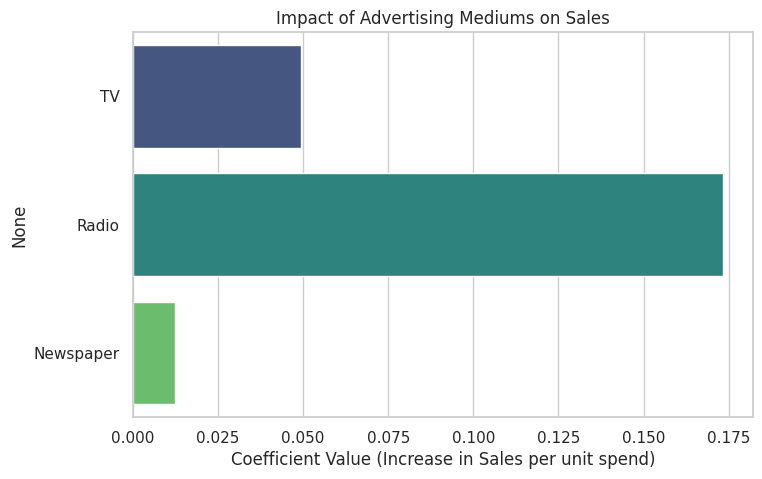

In [6]:
# Analyze Coefficients
coefficients = pd.DataFrame(model.coef_, X.columns, columns=['Coefficient'])
coefficients.loc['Intercept'] = model.intercept_
print("Model Coefficients and Intercept:")
display(coefficients)

# Plot feature importance
plt.figure(figsize=(8, 5))
sns.barplot(x=model.coef_, y=X.columns, palette='viridis')
plt.title('Impact of Advertising Mediums on Sales')
plt.xlabel('Coefficient Value (Increase in Sales per unit spend)')
plt.show()